Analysis of Retail dataset

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

Creating dataframe

In [7]:
df = pd.read_excel("../data/Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Cleaning the data

In [8]:
# Removing cancelled transactions from the dataframe (InvoiceNo values beginning with the letter C)
df_cleaned = df[~df['InvoiceNo'].astype(str).str.startswith('C')].copy()

# Removing transactions with unit prices of 0 
df_cleaned = df_cleaned[df_cleaned['UnitPrice'] > 0].copy()

len(df_cleaned)

530104

Creating Revenue column

In [10]:
# Creating Revenue column
df_cleaned['Revenue'] = df_cleaned['Quantity'] * df_cleaned['UnitPrice']
df_cleaned[['Quantity', 'UnitPrice', 'Revenue']].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


Analysis

In [35]:
# Calculating Total overall revenue
print("Total Revenue: ", round(df_cleaned['Revenue'].sum(), 2))

Total Revenue:  10666684.54


In [19]:
# Calculating Monthly revenue by adding a Month column
df_cleaned['Month'] = df_cleaned['InvoiceDate'].dt.to_period('M')
df_cleaned.groupby('Month')['Revenue'].sum().sort_values(ascending=False)

Month
2011-11    1509496.330
2011-10    1154979.300
2011-09    1058590.172
2010-12     823746.140
2011-05     770536.020
2011-06     761739.900
2011-08     759138.380
2011-07     719221.191
2011-03     717639.360
2011-01     691364.560
2011-12     638792.680
2011-04     537808.621
2011-02     523631.890
Freq: M, Name: Revenue, dtype: float64

In [11]:
# Filtering out non products
non_products = ['POSTAGE', 'DOTCOM POSTAGE', 'Manual', 'BANK CHARGES', 'AMAZON FEE']
df_clean_products = df_cleaned[~df_cleaned['Description'].isin(non_products)].copy()

# Finding out which products generated the most money
df_clean_products.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10)

Description
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66964.99
PAPER CHAIN KIT 50'S CHRISTMAS         64952.29
ASSORTED COLOUR BIRD ORNAMENT          59094.93
CHILLI LIGHTS                          54117.76
Name: Revenue, dtype: float64

In [43]:
# Finding out which countries generated the most revenue
df_cleaned.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10)

Country
United Kingdom    9025222.084
Netherlands        285446.340
EIRE               283453.960
Germany            228867.140
France             209715.110
Australia          138521.310
Spain               61577.110
Switzerland         57089.900
Belgium             41196.340
Sweden              38378.330
Name: Revenue, dtype: float64

In [69]:
# Calculating average order value (AOV)
order_totals = df_cleaned.groupby('InvoiceNo')['Revenue'].sum()
aov = order_totals.mean()
print(f"Average Order Value: £{aov:.2f}")

Average Order Value: £534.40


Visualizations

<Axes: ylabel='Description'>

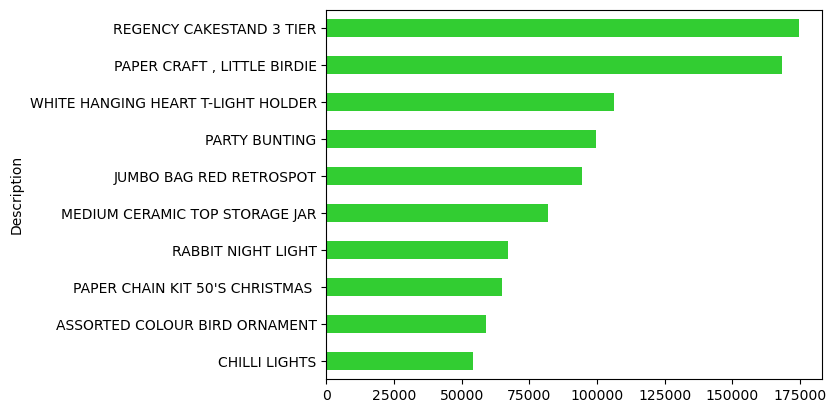

In [55]:
# Top 10 products by revenue
top_10_products = df_clean_products.groupby('Description')['Revenue'].sum().nlargest(10).sort_values()
top_10_products.plot.barh(color='limegreen')

<Axes: xlabel='InvoiceDate'>

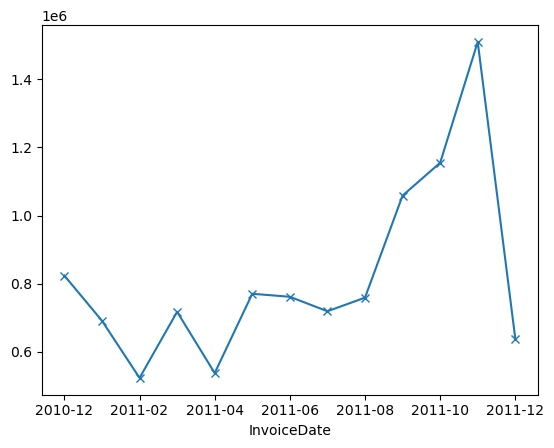

In [54]:
# Monthly revenue over time
monthly_revenue = df_cleaned.groupby(df_cleaned['InvoiceDate'].dt.to_period('M'))['Revenue'].sum()
monthly_revenue.index = monthly_revenue.index.astype(str)
monthly_revenue.plot(kind='line', marker='x')

<Axes: xlabel='Country'>

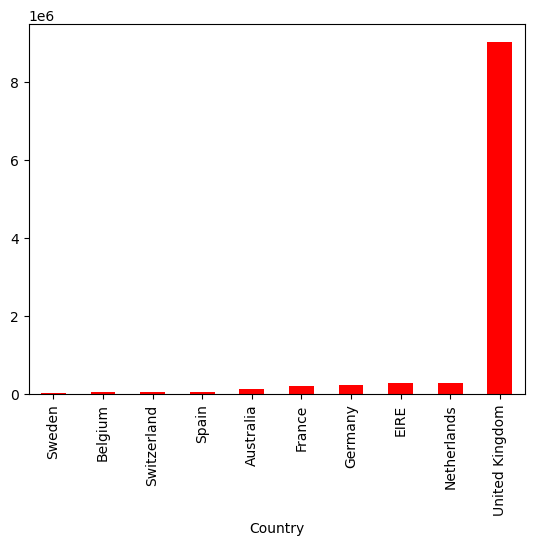

In [56]:
# Top 10 countries by revenue
top_10_countries = df_cleaned.groupby('Country')['Revenue'].sum().nlargest(10).sort_values()
top_10_countries.plot.bar(color='red')

SQL database

In [12]:
# Creating sql database
conn = sqlite3.connect("retail_analysis.db")

# Adding the data
df_clean_products.to_sql("sales", conn, if_exists="replace", index=False)

527948

SQL queries

In [35]:
# Total number of transactions
query1 = """
SELECT COUNT(DISTINCT invoiceno) AS "Number of transactions"
FROM sales;
"""

result1 = pd.read_sql(query1, conn)
result1

,Number of transactions
0,19790


In [37]:
# Number of unique customers
query2 = """
SELECT COUNT(DISTINCT customerID) AS "Number of unique customers"
FROM sales;
"""

result2 = pd.read_sql(query2, conn)
result2

,Number of unique customers
0,4335


In [40]:
# Finding the 10 largest individual orders
query3 = """
SELECT invoiceno, SUM(revenue) AS total_revenue
FROM sales
GROUP BY invoiceno
ORDER BY total_revenue DESC
LIMIT 10;
"""

result3 = pd.read_sql(query3, conn)
result3

,InvoiceNo,total_revenue
0,581483,168469.60
1,541431,77183.60
2,574941,52940.94
3,576365,50653.91
4,556444,38970.00
5,567423,31698.16
6,556917,22775.93
7,572209,22206.00
8,567381,22104.80
9,563614,21880.44


In [60]:
# Percentage of total revenue that comes from the top 10 products
query4 = """
SELECT (top_10_revenue / (SELECT SUM(revenue) FROM sales)) * 100 AS percentage_of_total_revenue
FROM (SELECT SUM(total_revenue) AS top_10_revenue
FROM (SELECT description, SUM(revenue) AS total_revenue
FROM sales
GROUP BY description
ORDER BY total_revenue DESC
LIMIT 10));
"""

result4 = pd.read_sql(query4, conn)
result4

,percentage_of_total_revenue
0,9.425452


In [68]:
# How many orders does each customer have?
query5 = """
SELECT customerid, COUNT(DISTINCT invoiceno) AS number_of_orders
FROM sales
WHERE customerid IS NOT NULL
GROUP BY customerid;
"""

result5 = pd.read_sql(query5, conn)
result5

,CustomerID,number_of_orders
0,12346.0,1
1,12347.0,7
2,12348.0,4
3,12349.0,1
4,12350.0,1
...,...,...
4330,18280.0,1
4331,18281.0,1
4332,18282.0,2
4333,18283.0,16


In [13]:
# Closing connection to database
conn.close()